# 01 · Data audit — what we were given, and what we decided because of it

Before building anything, I audited the 100 sample transcripts on seven questions:

1. **Format** — is the schema consistent and internally coherent?
2. **Speaker labels** — are speakers named, and can we tell customer from Aegis staff?
3. **Call-type mix** — the brief expects support / external / internal; what's actually here?
4. **Length distribution** — anything that would break or bias an LLM/clustering pipeline?
5. **Metadata** — dates, accounts, agents, products: present, derivable, or missing?
6. **PII** — what sensitive data is in the text, and what must be handled before calling an external LLM?
7. **Duplicates** — exact or near-duplicate calls that would skew counts?

Each section ends with a **Decision** box: *what I found → what I did about it.*

In [1]:
import re, itertools, hashlib
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transcript_intel.data import load_raw, build_tables, CORE_PRODUCTS

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TYPE_ORDER = ["support", "external", "internal"]

raw = load_raw()
calls, sentences, moments = build_tables(raw)
print(f"{len(raw)} calls · {len(sentences):,} transcript lines · {len(moments)} provided key moments")

100 calls · 4,313 transcript lines · 402 provided key moments


## 1. Format

Each call folder has six JSON files: `meeting-info`, `transcript`, `summary`, `speakers`, `speaker-meta`, `events`.
First check: does every file have the same key structure across all 100 calls?

In [2]:
def keyset(o):
    return tuple(sorted(o)) if isinstance(o, dict) else type(o).__name__

schemas = defaultdict(Counter)
for mid, f in raw.items():
    schemas["meeting-info"][keyset(f["meeting-info"])] += 1
    schemas["summary"][keyset(f["summary"])] += 1
    for s in f["transcript"]["data"]: schemas["transcript line"][keyset(s)] += 1
    for e in f["events"]: schemas["event"][keyset(e)] += 1
    for k in f["summary"]["keyMoments"]: schemas["key moment"][keyset(k)] += 1

pd.DataFrame([{"object": k, "distinct schemas": len(v), "rows": sum(v.values()), "keys": ", ".join(v.most_common(1)[0][0])}
              for k, v in schemas.items()])

,object,distinct schemas,rows,keys
0,meeting-info,1,100,"allEmails, duration, endTime, host, invitees, meetingId, organizerEmail, startTime, title"
1,summary,1,100,"actionItems, keyMoments, meetingId, overallSentiment, sentimentScore, summary, topics"
2,transcript line,1,4313,"averageConfidence, endTime, index, sentence, sentimentType, speaker_id, speaker_name, time"
3,event,1,622,"participantName, time, timestamp, type"
4,key moment,1,402,"speaker, text, time, type"


In [3]:
# Internal coherence checks
checks = {
    "meetingId matches folder": all(f["meeting-info"]["meetingId"] == mid == f["summary"]["meetingId"] for mid, f in raw.items()),
    "line index contiguous": all([s["index"] for s in f["transcript"]["data"]] == list(range(len(f["transcript"]["data"]))) for f in raw.values()),
    "lines time-ordered": sentences.groupby("meeting_id")["start_s"].apply(lambda s: s.is_monotonic_increasing).all(),
    "no overlapping turns": not any((g["start_s"].shift(-1) < g["end_s"]).any() for _, g in sentences.groupby("meeting_id")),
    "no empty sentences": (sentences["text"].str.strip() != "").all(),
    "speakers.json == transcript turns": all([(s["speakerName"], s["timestamp"]) for s in f["speakers"]] ==
                                             [(s["speaker_name"], s["time"]) for s in f["transcript"]["data"]] for f in raw.values()),
}
pd.Series(checks, name="passes").to_frame()

,passes
meetingId matches folder,True
line index contiguous,True
lines time-ordered,True
no overlapping turns,True
no empty sentences,True
speakers.json == transcript turns,True


In [4]:
print("Line-level sentiment labels:", sentences["sentiment"].value_counts(normalize=True).round(2).to_dict())
print("ASR confidence:", sentences["asr_conf"].describe()[["min", "50%", "max"]].round(2).to_dict())
print("Provided overall label → score band:")
calls.groupby("overall_sentiment")["sentiment_score"].agg(["min", "max", "count"]).sort_values("min")

Line-level sentiment labels: {'neutral': 0.56, 'positive': 0.27, 'negative': 0.17}
ASR confidence: {'min': 0.88, '50%': 0.92, 'max': 0.97}
Provided overall label → score band:


,min,max,count
overall_sentiment,,,
very-negative,1.4,1.6,2
negative,1.8,1.8,4
mixed-negative,2.1,2.8,33
mixed-positive,3.2,4.2,33
positive,4.1,4.5,7
very-positive,4.7,4.9,21


### The big format issue: transcripts are partial

`duration` in meeting-info is the scheduled length. Comparing it with the last spoken timestamp shows
the transcripts cover only a fraction of each meeting — and many provided key moments point past the end of the text.

Transcript coverage (spoken / scheduled): {'min': 0.15, '25%': 0.23, '50%': 0.29, '75%': 0.43, 'max': 0.9}
Key moments timestamped after the transcript ends: 107 / 402


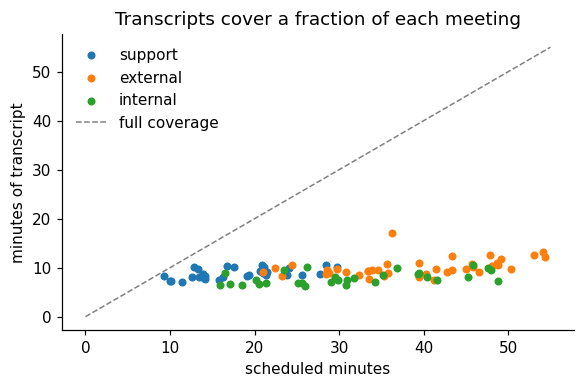

In [5]:
print("Transcript coverage (spoken / scheduled):", calls["coverage"].describe()[["min", "25%", "50%", "75%", "max"]].round(2).to_dict())
print(f"Key moments timestamped after the transcript ends: {moments['beyond_transcript'].sum()} / {len(moments)}")

fig, ax = plt.subplots(figsize=(6, 3.5))
for t in TYPE_ORDER:
    d = calls[calls.call_type == t]
    ax.scatter(d["scheduled_min"], d["spoken_min"], label=t, s=18)
ax.plot([0, 55], [0, 55], ls="--", c="grey", lw=1, label="full coverage")
ax.set(xlabel="scheduled minutes", ylabel="minutes of transcript", title="Transcripts cover a fraction of each meeting")
ax.legend(frameon=False); plt.show()

In [6]:
# Does the provided overall score agree with the line-level labels we *can* see?
net = (sentences.assign(v=sentences["sentiment"].map({"positive": 1, "neutral": 0, "negative": -1}))
                .groupby("meeting_id")["v"].mean())
r = np.corrcoef(net.loc[calls.meeting_id], calls["sentiment_score"])[0, 1]
print(f"corr(line-level net sentiment, provided overall score) = {r:.2f}")

corr(line-level net sentiment, provided overall score) = 0.94


> **Decision — Format**
> - *Found:* schema is 100% consistent and coherent, **but** transcripts cover a median ~29% of the scheduled meeting and 107/402 provided key moments sit beyond the transcript.
>   → *Decided:* treat **transcript text as the source of truth**; use provided summaries/key moments as unverifiable metadata and never rely on their timestamps. Don't present `duration` as talk time.
> - *Found:* provided overall score tracks line-level sentiment closely (r ≈ 0.94) with clean label→score bands.
>   → *Decided:* reuse provided sentiment as the baseline instead of re-scoring; add value by slicing it (speaker side, call phase, time, account).

## 2. Speaker labels

Are speakers named, and can every speaker be tied to an attendee email (and therefore to Aegis vs customer)?

In [7]:
generic = sentences["speaker"].str.match(r"(?i)^(speaker|unknown|participant|guest)\s*\d*$")
print("Generic labels (e.g. 'Speaker 1'):", int(generic.sum()))
print("Speakers per call:", calls["n_speakers"].value_counts().sort_index().to_dict())
print("Attendee count == speaker count in every call:", (calls["n_attendees"] == calls["n_speakers"]).all())
spk = sentences.drop_duplicates(["meeting_id", "speaker"])
print(f"Speakers matched to an attendee email: {spk['speaker_email'].notna().sum()} / {len(spk)}")
print("Speaker side:", spk["side"].value_counts().to_dict())

Generic labels (e.g. 'Speaker 1'): 0
Speakers per call: {2: 30, 3: 38, 4: 23, 5: 9}
Attendee count == speaker count in every call: True
Speakers matched to an attendee email: 311 / 311
Speaker side: {'aegis': 224, 'customer': 87}


In [8]:
# Email conventions differ by side — the naive first.last match only catches staff
spk.assign(local=spk["speaker_email"].str.split("@").str[0])[["speaker", "speaker_email", "side"]].groupby("side").head(3)

,speaker,speaker_email,side
0,Megan Lawson,megan.lawson@aegiscloud.com,aegis
1,Raj Kapoor,raj.kapoor@aegiscloud.com,aegis
2,Brian Cho,brian.cho@aegiscloud.com,aegis
44,Gregory Fisk,g.fisk@summittrust.com,customer
123,Thomas Hargrove,t.hargrove@redwoodclinical.com,customer
162,Lauren Bishop,l.bishop@cobaltsoftware.com,customer


In [9]:
talk = sentences.assign(sec=sentences.end_s - sentences.start_s).groupby(["meeting_id", "speaker"])["sec"].sum()
top_share = (talk / talk.groupby(level=0).transform("sum")).groupby(level=0).max()
print("Top speaker's share of talk time:", top_share.describe()[["min", "50%", "max"]].round(2).to_dict())

Top speaker's share of talk time: {'min': 0.29, '50%': 0.44, 'max': 0.66}


> **Decision — Speaker labels**
> - *Found:* every line has a real name; all 311 speakers map to an attendee email once you allow for the two conventions (staff `first.last@`, customers `f.last@`). No call is a monologue (top speaker ≤ 66% of talk time).
>   → *Decided:* add a **`side` column (aegis / customer)** to every line. This lets us measure *customer* sentiment separately from our own staff, whose tone is polite by default and would dilute the signal.

## 3. Actual call-type mix

There is **no call-type field**. I derive it with two transparent rules:
1. All attendees on `aegiscloud.com` → **internal**
2. Otherwise, title starts with `Support Case #` / `URGENT` / `ESCALATION` → **support**, else → **external** (account management)

In [10]:
mix = calls["call_type"].value_counts().reindex(TYPE_ORDER)
print(mix.to_dict())
calls.assign(prefix=calls.title.str.split(r" - | #|:", regex=True).str[0]).groupby("call_type")["prefix"] \
     .agg(lambda s: dict(Counter(s).most_common(4)))

{'support': 30, 'external': 40, 'internal': 30}


call_type
external    {'Aegis / Redwood Clinical': 2, 'Aegis / Atlas Precision': 2, 'Aegis / Blackridge Investments': 2, 'Aegis / Brightpa...
internal                                    {'Detect Outage': 5, 'Comply v2': 5, 'Detect Team': 3, 'Weekly Engineering Standup': 2}
support                                                                          {'Support Case': 27, 'URGENT': 2, 'ESCALATION': 1}
Name: prefix, dtype: object

In [11]:
# Edge cases: external calls whose title suggests incident / support work
calls.loc[(calls.call_type == "external") & calls.incident_flag, ["start", "title", "sentiment_score"]]

,start,title,sentiment_score
8,2026-03-19 16:00:00+00:00,Aegis / Quantum Edge - Renewal Concerns,2.4
18,2026-03-12 12:15:00+00:00,Aegis / Northstar Pharma - Urgent: Detect Outage Impact,2.1
44,2026-03-26 16:00:00+00:00,Aegis / Summit Trust - Platform Concerns Discussion,2.4
63,2026-03-17 11:45:00+00:00,Aegis / Helix Data - Post-Incident Review,2.3


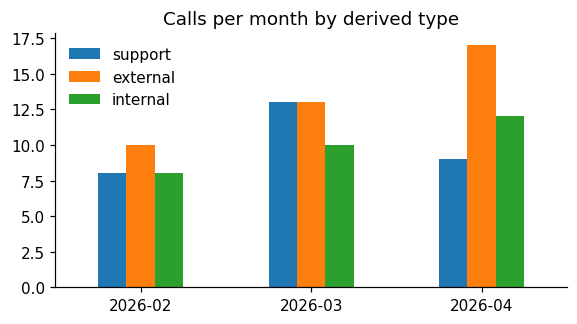

call_type,support,external,internal
start,,,
2026-02,8,10,8
2026-03,13,13,10
2026-04,9,17,12


In [12]:
by_month = pd.crosstab(calls.start.dt.strftime("%Y-%m"), calls.call_type)[TYPE_ORDER]
ax = by_month.plot.bar(figsize=(6, 3), rot=0, title="Calls per month by derived type")
ax.legend(frameon=False); ax.set_xlabel(""); plt.show()
by_month

> **Decision — Call-type mix**
> - *Found:* all three types are present and balanced — **30 support · 40 external · 30 internal** — and stable month to month.
>   → *Decided:* **no synthetic data needed** to fill a missing type. Keep the rule-based label: it's 100% explainable and needs no model.
> - *Found:* 4 external calls (Northstar, Quantum Edge, Summit Trust, Helix) are really outage firefighting led by account managers.
>   → *Decided:* don't relabel them; add an **`incident_flag`** instead. AMs absorbing incident escalations is itself an insight about the outage's reach.

## 4. Length distribution

In [13]:
calls["wpm"] = calls["n_words"] / calls["spoken_min"]
calls.groupby("call_type")[["scheduled_min", "n_words", "n_turns", "wpm"]].median().reindex(TYPE_ORDER).round(1)

,scheduled_min,n_words,n_turns,wpm
call_type,,,,
support,17.2,1332.5,40.5,157.1
external,39.4,1520.5,43.5,157.5
internal,30.4,1160.0,41.0,153.5


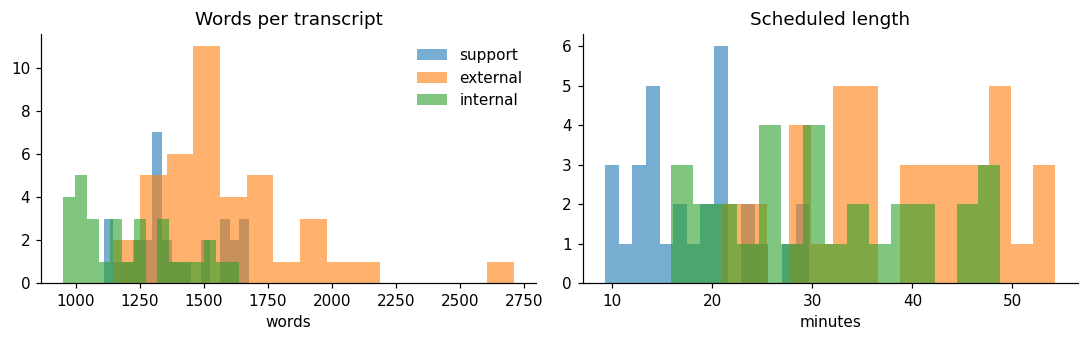

Word-count outliers (|z| > 2):
                                               title  n_words
Aegis / Harborview Banking - Threat Detection Tuning     2711
 Aegis / Summit Trust - Platform Concerns Discussion     2018
 Aegis / Blackridge Investments - Renewal Discussion     2126


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for t in TYPE_ORDER:
    axes[0].hist(calls.loc[calls.call_type == t, "n_words"], bins=15, alpha=.6, label=t)
    axes[1].hist(calls.loc[calls.call_type == t, "scheduled_min"], bins=15, alpha=.6, label=t)
axes[0].set(title="Words per transcript", xlabel="words"); axes[1].set(title="Scheduled length", xlabel="minutes")
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

z = (calls.n_words - calls.n_words.mean()) / calls.n_words.std()
print("Word-count outliers (|z| > 2):"); print(calls.loc[z.abs() > 2, ["title", "n_words"]].to_string(index=False))

In [15]:
# Signals that look like generation artifacts rather than real-world variation
print("Words/min range:", calls.wpm.min().round(0), "–", calls.wpm.max().round(0))
print("ASR confidence range:", sentences.asr_conf.min(), "–", sentences.asr_conf.max())
print(f"Weekend meetings: {(calls.start.dt.weekday >= 5).mean():.0%}")

Words/min range: 149.0 – 161.0
ASR confidence range: 0.88 – 0.97
Weekend meetings: 27%


> **Decision — Length**
> - *Found:* lengths are compact (≈950–2,700 words; 3 mild outliers), so every transcript fits comfortably in one LLM call.
>   → *Decided:* **no chunking or truncation** needed.
> - *Found:* speaking rate (≈149–161 wpm), ASR confidence (0.88–0.97) and 27% weekend meetings are implausibly uniform/unusual for real calls — the dataset is **synthetic**.
>   → *Decided:* **don't build insights on pace, ASR confidence or day-of-week** — those would be describing the generator, not the business.

## 5. Metadata — present, derivable, missing

In [16]:
print("Date range:", calls.start.min().date(), "→", calls.start.max().date())
acc = calls.dropna(subset=["account"])
print(f"Customer accounts (email domains): {acc.account.nunique()}")
print("Calls per account:", acc.account.value_counts().value_counts().sort_index().to_dict())
both = acc.groupby("account").call_type.agg(set).apply(lambda s: {"support", "external"} <= s)
print(f"Accounts with BOTH support and external calls: {both.sum()}")

Date range: 2026-02-03 → 2026-04-28
Customer accounts (email domains): 32
Calls per account: {1: 8, 2: 14, 3: 6, 4: 4}
Accounts with BOTH support and external calls: 20


In [17]:
staff = (sentences[sentences.side == "aegis"].drop_duplicates(["meeting_id", "speaker_email"])
         .groupby("speaker_email").call_type.agg(lambda s: dict(Counter(s))))
print(f"Aegis staff: {len(staff)}; appearing in all 3 call types: {sum(len(v) == 3 for v in staff)}")
staff.head(10)

Aegis staff: 27; appearing in all 3 call types: 0


speaker_email
aisha.johnson@aegiscloud.com     {'internal': 1, 'external': 7}
alex.reyes@aegiscloud.com                       {'internal': 3}
ananya.sharma@aegiscloud.com    {'internal': 10, 'external': 4}
brian.cho@aegiscloud.com                        {'internal': 6}
chris.lee@aegiscloud.com         {'internal': 6, 'external': 1}
daniel.okafor@aegiscloud.com     {'external': 7, 'internal': 1}
david.kim@aegiscloud.com                         {'support': 9}
diana.reeves@aegiscloud.com                     {'internal': 7}
elena.vasquez@aegiscloud.com                     {'support': 8}
hannah.liu@aegiscloud.com                       {'internal': 3}
Name: call_type, dtype: object

In [18]:
prod = pd.Series({p: calls.products.apply(lambda ps: p in ps).sum() for p in CORE_PRODUCTS}, name="calls mentioning")
print(prod.to_dict())
topics = Counter(t for ts in calls.topics for t in ts)
print(f"Provided topic tags: {len(topics)} distinct, {sum(v == 1 for v in topics.values())} used only once")
print("Top tags:", topics.most_common(8))

{'Detect': 74, 'Protect': 38, 'Identity': 37, 'Comply': 64}
Provided topic tags: 351 distinct, 266 used only once
Top tags: [('compliance', 23), ('compliance reporting', 19), ('renewal', 17), ('churn risk', 14), ('onboarding', 9), ('incident response', 8), ('outage', 8), ('incident communication', 7)]


In [19]:
pd.DataFrame([
    ("Date / time", "present", "meeting-info.startTime"),
    ("Customer account", "derivable", "attendee email domain (always matches title)"),
    ("Agent / staff", "present", "aegiscloud.com attendees, named per line"),
    ("Product", "derivable", "keyword match in transcript"),
    ("Call type", "derivable", "rules in section 3"),
    ("Topics", "present but unusable", "free-text tags, 76% singletons"),
    ("Staff role / team", "missing", "infer from which call types a person joins"),
    ("ARR, plan, renewal date", "missing", "only mentioned in speech, if at all"),
    ("CSAT, ticket status / resolution", "missing", "—"),
], columns=["field", "status", "source / workaround"])

,field,status,source / workaround
0,Date / time,present,meeting-info.startTime
1,Customer account,derivable,attendee email domain (always matches title)
2,Agent / staff,present,"aegiscloud.com attendees, named per line"
3,Product,derivable,keyword match in transcript
4,Call type,derivable,rules in section 3
5,Topics,present but unusable,"free-text tags, 76% singletons"
6,Staff role / team,missing,infer from which call types a person joins
7,"ARR, plan, renewal date",missing,"only mentioned in speech, if at all"
8,"CSAT, ticket status / resolution",missing,—


> **Decision — Metadata**
> - *Found:* 32 accounts; **20 have both support and external calls**, 24 have ≥2 calls.
>   → *Decided:* build **account-level timelines** (support pain → renewal conversation) — the most valuable cross-call-type view.
> - *Found:* no staff member appears in all three call types — roles are cleanly separated.
>   → *Decided:* infer staff role (support / AM / engineering) from call-type participation rather than inventing a field.
> - *Found:* provided topic tags are free text — 351 distinct, 266 used once.
>   → *Decided:* they can't serve as categories directly; this justifies a **clustering + LLM-naming** step for topic categorisation (notebook 02).

## 6. PII

We plan to send transcript text to an external LLM API, so I scanned spoken text and summaries for structured PII
and checked each hit in context rather than trusting regex counts.

In [20]:
PII = {
    "email": r"[\w.+-]+@[\w-]+\.[\w.]+",
    "phone": r"(?<!\d)(?:\+?1[\s.-]?)?\(?\d{3}\)?[\s.-]\d{3}[\s.-]\d{4}(?!\d)",
    "ssn": r"\b\d{3}-\d{2}-\d{4}\b",
    "credit card": r"\b(?:\d[ -]?){13,16}\b",
    "ip address": r"\b(?:\d{1,3}\.){3}\d{1,3}\b",
    "street address": r"\b\d{2,5}\s+[A-Z][a-z]+\s+(?:Street|St|Avenue|Ave|Road|Rd|Blvd|Drive|Lane)\b",
    "secret / api key": r"\b(?:sk|pk|api|key|token)[-_][A-Za-z0-9]{8,}\b",
    "account / ticket id": r"\b[A-Z]{2,4}-\d{4,}\b",
    "case / invoice no.": r"(?i)\b(?:case|invoice|ticket)\s*(?:number|no\.?|#)?\s*\d{3,}",
    "money amount": r"\$\s?\d[\d,]*(?:\.\d+)?",
    "health terms": r"(?i)\b(?:patient|diagnos\w*|medical record|MRN|date of birth)\b",
}
corpus = pd.concat([sentences[["meeting_id", "text"]],
                    calls[["meeting_id", "summary"]].rename(columns={"summary": "text"})])
rows = []
for k, rx in PII.items():
    m = corpus.text.str.findall(rx).explode().dropna()
    rows.append({"type": k, "hits": len(m), "examples": list(dict.fromkeys(m))[:4]})
pd.DataFrame(rows)

,type,hits,examples
0,email,0,[]
1,phone,0,[]
2,ssn,0,[]
3,credit card,0,[]
4,ip address,0,[]
5,street address,0,[]
6,secret / api key,0,[]
7,account / ticket id,15,"[INV-2026, BRI-04471, AGS-229183, RLL-4482]"
8,case / invoice no.,32,"[case number 9279, case 9279, case number 6977, invoice 8847]"
9,money amount,28,"[$0.004, $480,, $360, $310]"


In [21]:
# Context check for the hits that matter
for rx in [r"\b[A-Z]{2,4}-\d{4,}\b", r"(?i)\bpatient", r"(?i)invoice \d+"]:
    hit = sentences[sentences.text.str.contains(rx)].head(2)
    for t in hit.text: print(f"[{rx}] …{t[:150]}")

[\b[A-Z]{2,4}-\d{4,}\b] …Um, give me just a second... yeah, it's INV-2026-00847.
[\b[A-Z]{2,4}-\d{4,}\b] …Perfect, INV-2026-00847, let me bring that up... okay, I can see the invoice. And yeah, I can see the Identity module line item — 1,400 seats at the p
[(?i)\bpatient] …Yeah, so HIPAA is definitely the big one, that's non-negotiable for us — but we also process some payment data through our patient portal so PCI DSS i
[(?i)\bpatient] …We first noticed it around 6 AM this morning, March 15th. The event feed just... stopped. No incoming threat events, the monitoring panel looks comple
[(?i)invoice \d+] …I've got them — it's invoice 8847 and 8901. Both from January and February respectively.


In [22]:
# Names spoken on a call that belong to someone NOT on that call (third-party mentions)
first_names = {n.split()[0] for n in sentences.speaker.unique()}
on_call = sentences.groupby("meeting_id").speaker.agg(lambda s: {n.split()[0] for n in s})
third = Counter()
for mid, text in zip(sentences.meeting_id, sentences.text):
    for w in re.findall(r"\b([A-Z][a-z]{2,})(?:'s)?\b", text):
        if w in first_names and w not in on_call[mid]:
            third[w] += 1
print(f"Third-party name mentions: {sum(third.values())}", third.most_common(6))

Third-party name mentions: 63 [('Priya', 29), ('Marcus', 21), ('Raj', 6), ('Sarah', 3), ('Rachel', 3), ('Aisha', 1)]


> **Decision — PII**
> - *Found:* **no** emails, phone numbers, SSNs, card numbers, IPs, addresses or secrets in spoken text. Healthcare customers mention "patient data" only in a compliance sense — no actual PHI.
> - *Found:* **present** — full names (incl. 63 mentions of colleagues not on the call), account/ticket IDs (`BRI-04471`, `AGS-229183`), case and invoice numbers, contract amounts.
>   → *Decided:* before any text goes to the Claude API, **mask account/ticket/case/invoice IDs and pseudonymise customer contact names**. Keep company names — account-level insights depend on them — and keep dollar amounts, which carry pricing signal.

## 7. Duplicates and near-duplicates

Exact duplicates by hash; near-duplicates by 5-word-shingle Jaccard similarity across all 4,950 call pairs.

In [23]:
norm = lambda s: re.sub(r"[^a-z0-9 ]", "", s.lower())
full = sentences.groupby("meeting_id").text.apply(lambda s: norm(" ".join(s)))
print("Exact duplicate transcripts:", int(full.map(lambda t: hashlib.md5(t.encode()).hexdigest()).duplicated().sum()))
print("Repeated titles:", calls.title.value_counts().loc[lambda s: s > 1].to_dict())

shingles = {mid: {" ".join(w[i:i+5]) for w in [t.split()] for i in range(len(w) - 4)} for mid, t in full.items()}
title = calls.set_index("meeting_id").title
pairs = sorted(((len(shingles[a] & shingles[b]) / len(shingles[a] | shingles[b]), title[a], title[b])
                for a, b in itertools.combinations(shingles, 2)), reverse=True)
print(f"Pairs with Jaccard > 0.10: {sum(j > .1 for j, *_ in pairs)}")
pd.DataFrame(pairs[:5], columns=["jaccard", "call A", "call B"]).round(3)

Exact duplicate transcripts: 0
Repeated titles: {'Weekly Engineering Standup': 2, 'Detect Team - Sprint Planning': 2}


Pairs with Jaccard > 0.10: 0


,jaccard,call A,call B
0,0.015,URGENT: Blackridge Investments - Complete Loss of Threat Visibility,URGENT: Cobalt Software - Aegis Detect Dashboard Down
1,0.013,Aegis / Meridian Capital - Service Reliability Discussion,Aegis / Nova Retail Group - Renewal Discussion
2,0.013,Aegis / Steelpoint Manufacturing - Contract Review,Aegis / Nova Retail Group - Renewal Discussion
3,0.011,Aegis / Brightpath Commerce - Competitive Evaluation,Aegis / Nova Retail Group - Renewal Discussion
4,0.011,Aegis / Nova Retail Group - Renewal Discussion,Aegis / Ironclad Financial - Account Recovery Check-in


In [24]:
# Verbatim sentence reuse across calls = templated boilerplate
reuse = (sentences.assign(n=sentences.text.map(norm)).loc[lambda d: d.n.str.split().str.len() >= 6]
         .groupby("n").meeting_id.nunique().loc[lambda s: s > 1])
print("Sentences reused verbatim in >1 call:"); print(reuse.to_string())
print("\nMost common opening lines:", Counter(sentences[sentences.idx == 0].text.map(norm).str[:40]).most_common(3))

Sentences reused verbatim in >1 call:
n
thank you for calling aegis cloud security support this is david kim how can i help you today    2
yeah loud and clear good to go                                                                   2

Most common opening lines: [('alright i think weve got everyone on now', 5), ('thank you for calling aegis cloud securi', 4), ('alright i think were all here  let me ju', 2)]


> **Decision — Duplicates**
> - *Found:* **no exact or near-duplicates** — the most similar pair shares 1.5% of 5-word shingles. Repeated titles are recurring meetings with different content.
>   → *Decided:* **keep all 100 calls**; no deduplication.
> - *Found:* the only repetition is templated greetings ("Thank you for calling Aegis Cloud Security support…", "Alright, I think we've got everyone…").
>   → *Decided:* **strip opening/closing pleasantries before clustering**, so support calls don't group together on boilerplate rather than substance.

## Summary — what the audit changes in the pipeline

| Finding | Decision |
|---|---|
| Transcripts cover ~29% of scheduled time; 107 key moments point past the text | Transcript text is source of truth; provided summaries are metadata only |
| Provided sentiment agrees with line labels (r ≈ 0.94) | Reuse it as baseline; add value via speaker-side, phase, time and account slices |
| All speakers map to emails | New `side` column → customer vs Aegis sentiment |
| 30 support / 40 external / 30 internal (derived) | Rule-based call type; no synthetic data needed; `incident_flag` for 4 edge cases |
| Uniform pace / ASR / weekend calls → synthetic | No insights on pace, ASR or weekday |
| 351 free-text topic tags, 76% singletons | Clustering + LLM naming for categories |
| 20 accounts have support + external calls | Account timelines as a headline insight |
| IDs, names, amounts in text; no hard PII | Mask IDs + pseudonymise contacts before LLM calls |
| No duplicates; only greeting boilerplate | Keep all 100; strip boilerplate before clustering |